# K-Means Clustering: Flow Velocity vs Heat Transfer Coefficient
K-Means clustering is used to group the nanofluid data points based on Flow Velocity (m/s) and Heat Transfer Coefficient (W/m²K).
The number of clusters is selected using the Elbow Method and checked with the Silhouette Score.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Loading the dataset 
data = pd.read_excel("../data/nanofluid_dataset.xlsx")


data.columns = [col.replace('Â','') for col in data.columns]
data

,Nanoparticle_Type,Base_Fluid,Volume_Fraction (%),Temperature (°C),Flow_Velocity (m/s),Thermal_Conductivity (W/mK),Specific_Heat_Capacity (J/kgK),Density (kg/m³),Viscosity (Pa·s),Heat_Transfer_Coefficient (W/m²K)
0,CuO,Propylene Glycol,2.80,85.8,1.907,0.645,3356,1255,0.00901,2234.978690
1,SiO2,Water,2.77,71.6,0.681,1.622,3366,1402,0.00650,2118.965000
2,Al2O3,Propylene Glycol,2.56,90.0,1.526,1.809,1398,1973,0.00989,3321.034199
3,SiO2,Propylene Glycol,1.64,78.3,0.166,1.907,2408,1994,0.00546,1222.944448
4,CuO,Oil,2.11,61.0,2.316,0.600,2370,1701,0.00328,4796.976529
...,...,...,...,...,...,...,...,...,...,...
10288,SiO2,Oil,3.00,88.2,2.434,1.816,2872,1001,0.00168,6343.370655
10289,CuO,Ethylene Glycol,0.86,83.1,0.765,0.794,1535,1391,0.00414,1813.314501
10290,SiO2,Propylene Glycol,3.72,29.8,2.705,1.564,2380,1848,0.00193,7693.288592
10291,Al2O3,Oil,4.51,50.6,1.303,0.698,4217,1491,0.00190,2082.559663


In [2]:
# Selected the two columns required for clustering as per the given question
# The goal is to group data points based on flow velocity and heat transfer coefficient.
A_Cluster = data[["Flow_Velocity (m/s)", "Heat_Transfer_Coefficient (W/m²K)"]]
A_Cluster.describe()

,Flow_Velocity (m/s),Heat_Transfer_Coefficient (W/m²K)
count,10293.000000,10293.000000
mean,1.534519,3844.768222
std,0.838257,3090.440626
min,0.099000,94.794840
25%,0.802000,1649.156665
50%,1.533000,3043.325713
75%,2.267000,5109.924566
max,3.082000,28432.138160


In [3]:
# Standardizing both the columns so that both contribute equally to the distance
scaler = StandardScaler()
A_Cluster_scaled = scaler.fit_transform(A_Cluster)

## Elbow Method

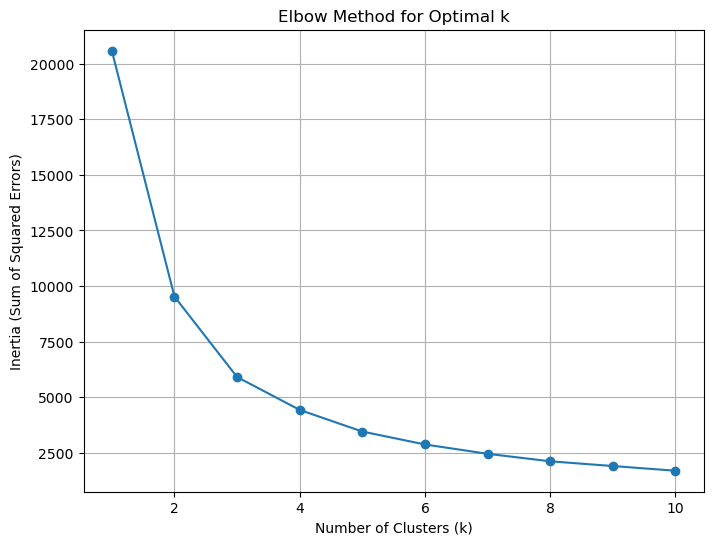

In [4]:
# Now,we Use the elbow method to find the optimal number of clusters (k).
# We calculate the inertia for a range of k values (from 1 to 10).
inertia_values = []
cluster_range = range(1, 11) 
for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=0, n_init=10)
    kmeans.fit(A_Cluster_scaled)
    inertia_values.append(kmeans.inertia_)
    
# Plot the elbow curve to visually identify the "elbow" point.
plt.figure(figsize=(8, 6))
plt.plot(cluster_range, inertia_values, marker='o')
plt.title("Elbow Method for Optimal k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia (Sum of Squared Errors)")
plt.grid(True)
plt.show()

k = 2 | Silhouette Score = 0.482
k = 3 | Silhouette Score = 0.470
k = 4 | Silhouette Score = 0.415
k = 5 | Silhouette Score = 0.412
k = 6 | Silhouette Score = 0.413
k = 7 | Silhouette Score = 0.389
k = 8 | Silhouette Score = 0.385
k = 9 | Silhouette Score = 0.385
k = 10 | Silhouette Score = 0.387


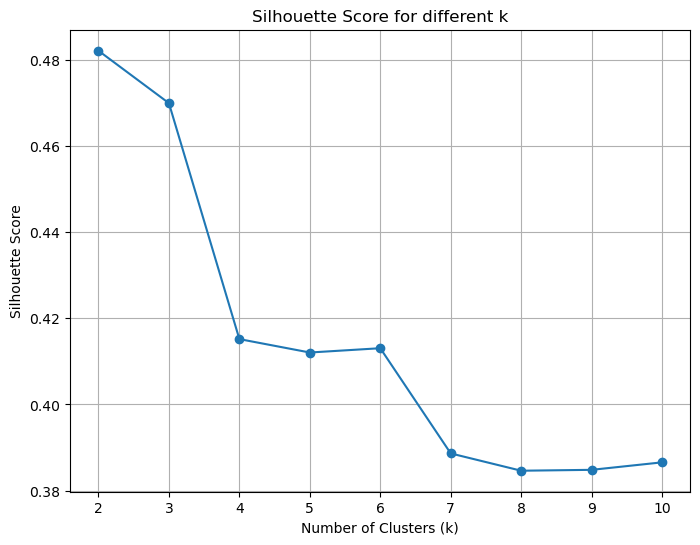

In [5]:
# Calculating the silhouette score for k values from 2 to 10 (it is not defined for k=1)
silhouette_values = []
silhouette_range = range(2, 11)
for k in silhouette_range:
    kmeans = KMeans(n_clusters=k, random_state=0, n_init=10)
    labels = kmeans.fit_predict(A_Cluster_scaled)
    score = silhouette_score(A_Cluster_scaled, labels)
    silhouette_values.append(score)
    print(f"k = {k} | Silhouette Score = {score:.3f}")

plt.figure(figsize=(8, 6))
plt.plot(silhouette_range, silhouette_values, marker='o')
plt.title("Silhouette Score for different k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

## K-Means with the Selected k

In [6]:
# The elbow curve bends between k=2 and k=3 and the silhouette scores of k=2 and k=3 are almost the same.
# k=3 is selected as it gives three groups that are easy to interpret (low, medium and high heat transfer).
optimal_k = 3

# Run KMeans again with the chosen number of clusters.
kmeans_final = KMeans(n_clusters=optimal_k, random_state=0, n_init=10)
clusters = kmeans_final.fit_predict(A_Cluster_scaled)

In [7]:
# Add the cluster labels to the original DataFrame for reference.
data["Cluster"] = clusters

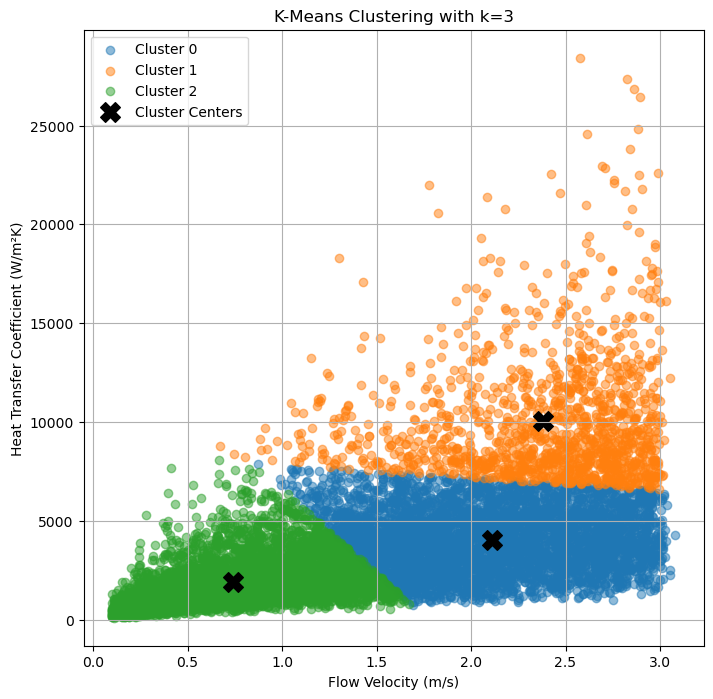

In [8]:
# Plotting the final clustered data, with each cluster in a different color.
plt.figure(figsize=(8, 8))
for cluster_id in range(optimal_k):
    # Select data points belonging to the current cluster
    cluster_points = A_Cluster[data["Cluster"] == cluster_id]
    plt.scatter(cluster_points.iloc[:, 0], cluster_points.iloc[:, 1], alpha=0.5, label=f'Cluster {cluster_id}')

# Plot the cluster centers to visualize the centroids.
centers = scaler.inverse_transform(kmeans_final.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='black', marker='X', s=200, label='Cluster Centers')

plt.title(f"K-Means Clustering with k={optimal_k}")
plt.xlabel("Flow Velocity (m/s)")
plt.ylabel("Heat Transfer Coefficient (W/m²K)")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
# Summary of each cluster in the original units
cluster_summary = data.groupby("Cluster")[["Flow_Velocity (m/s)", "Heat_Transfer_Coefficient (W/m²K)"]].agg(['mean', 'min', 'max'])
cluster_summary["Number of points"] = data["Cluster"].value_counts().sort_index()
cluster_summary.round(2)

Flow_Velocity (m/s)             Heat_Transfer_Coefficient (W/m²K)  \
                       mean   min   max                              mean   
Cluster                                                                     
0                      2.11  0.87  3.08                           4043.09   
1                      2.38  0.67  3.05                          10045.50   
2                      0.74  0.10  1.67                           1882.48   

                           Number of points  
             min       max                   
Cluster                                      
0         730.26   7873.34             4380  
1        6608.94  28432.14             1315  
2          94.79   8059.00             4598